# Olist Brazil E-commerce: Delivery Days Regression

**Objective:** Predict `actual_delivery_days` for completed orders, beating Olist's own `estimated_delivery_days` baseline.

**Dataset:** `olist_merged_clean.csv` — 96,189 completed orders (2016–2018)  
**Target:** `actual_delivery_days` (continuous float)  
**Split:** Temporal — Train: 2017 orders | Test: H2-2018 orders  
**Leakage Control:** `include_leakage=0` (production) vs `include_leakage=1` (sanity check)

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import warnings
warnings.filterwarnings('ignore')

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor
import shap

print('Libraries loaded successfully.')

Libraries loaded successfully.


In [8]:
# DATA_PATH = 'brazil_ecommerce\datasets\processed\olist_merged_clean.csv'
DATA_PATH = r'C:\Users\Admin\OneDrive\Desktop\Coursework\semester 6\AML Business\Project\AMLB\brazil_ecommerce\datasets\processed\olist_merged_clean.csv'
df = pd.read_csv(DATA_PATH)
print(f'Shape: {df.shape}')
print(f'Columns: {df.columns.tolist()}')
df.head(3)

Shape: (96189, 34)
Columns: ['order_id', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'is_late', 'n_items', 'total_price', 'total_freight', 'max_weight_g', 'max_length_cm', 'max_height_cm', 'max_width_cm', 'product_photos_qty', 'primary_category', 'customer_zip_code_prefix', 'customer_city', 'customer_state', 'seller_zip_code_prefix', 'seller_city', 'seller_state', 'payment_value', 'payment_installments', 'payment_type', 'customer_lat', 'customer_lng', 'seller_lat', 'seller_lng', 'distance_km', 'actual_delivery_days', 'estimated_delivery_days', 'delivery_delay_days', 'same_state']


,order_id,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,is_late,n_items,total_price,total_freight,...,payment_type,customer_lat,customer_lng,seller_lat,seller_lng,distance_km,actual_delivery_days,estimated_delivery_days,delivery_delay_days,same_state
0,e481f51cbdc54678b7cc49136f2d6af7,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 11:59:59,0,1,29.99,8.72,...,voucher,-23.576983,-46.587161,-23.680729,-46.444238,18.576110,8.436574,16.044051,-7.607477,1
1,53cdb2fc8bc7dce0b6741e2150273451,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 11:59:59,0,1,118.70,22.76,...,boleto,-12.177924,-44.660711,-19.807681,-43.980427,851.495069,13.782037,19.637755,-5.855718,0
2,47770eb9100c2d0c44946d9cf07ec65d,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 11:59:59,0,1,159.90,19.22,...,credit_card,-16.745150,-48.514783,-21.363502,-48.229601,514.410666,9.394213,27.139699,-17.745486,0


In [9]:
# --- Parse dates ---
date_cols = ['order_purchase_timestamp', 'order_delivered_customer_date', 'order_estimated_delivery_date']
for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors='coerce')

# --- Target (compute if missing) ---
if 'actual_delivery_days' not in df.columns:
    df['actual_delivery_days'] = (
        df['order_delivered_customer_date'] - df['order_purchase_timestamp']
    ).dt.days

# --- Temporal features ---
df['month']      = df['order_purchase_timestamp'].dt.month
df['quarter']    = df['order_purchase_timestamp'].dt.quarter
df['is_weekend'] = df['order_purchase_timestamp'].dt.dayofweek.isin([5, 6]).astype(int)

# --- Encode categoricals ---
cat_cols = ['primary_category', 'payment_type', 'customer_state', 'seller_state']
df = pd.get_dummies(df, columns=cat_cols, drop_first=True)

# --- Drop rows with missing target ---
df = df.dropna(subset=['actual_delivery_days'])
df = df[df['actual_delivery_days'] > 0]

print('Data prepared.')
print(f'Rows after prep: {len(df)}')
print(f'Target stats:\n{df["actual_delivery_days"].describe()}')

Data prepared.
Rows after prep: 96189
Target stats:
count    96189.000000
mean        12.538347
std          9.530783
min          0.533414
25%          6.756250
50%         10.209329
75%         15.682731
max        209.628611
Name: actual_delivery_days, dtype: float64


In [10]:
# --- Build feature lists ---
BASE_FEATURES = [
     'distance_km', 'same_state',
    'n_items', 'total_price', 'total_freight',
    'max_weight_g', 'max_length_cm', 'max_height_cm', 'max_width_cm',
    'product_photos_qty', 'payment_installments',
    'month', 'quarter', 'is_weekend'
]

# Add one-hot encoded columns
encoded_cols = [
    c for c in df.columns
    if c.startswith(('primary_category_', 'payment_type_', 'customer_state_', 'seller_state_'))
]

FEATURES_NO_LEAKAGE   = BASE_FEATURES + encoded_cols
FEATURES_WITH_LEAKAGE = FEATURES_NO_LEAKAGE + ['is_late']

print(f'Feature count (no leakage):   {len(FEATURES_NO_LEAKAGE)}')
print(f'Feature count (with leakage): {len(FEATURES_WITH_LEAKAGE)}')

Feature count (no leakage):   135
Feature count (with leakage): 136


In [11]:
# --- Temporal Train-Test Split ---
train_mask = df['order_purchase_timestamp'].dt.year == 2017
test_mask  = (
    (df['order_purchase_timestamp'].dt.year == 2018) &
    (df['order_purchase_timestamp'].dt.month >= 7)
)

df_train = df[train_mask].copy()
df_test  = df[test_mask].copy()

y_train = df_train['actual_delivery_days']
y_test  = df_test['actual_delivery_days']

print(f'Train size: {len(df_train):,} orders (2017)')
print(f'Test  size: {len(df_test):,} orders (H2 2018)')

Train size: 43,412 orders (2017)
Test  size: 12,507 orders (H2 2018)


In [12]:
# --- Mode 0: No Leakage (Production) ---
include_leakage = 0
features = [f for f in FEATURES_NO_LEAKAGE if f in df.columns]

X_train = df_train[features].fillna(0)
X_test  = df_test[features].fillna(0)

# Olist baseline
baseline_rmse = np.sqrt(mean_squared_error(y_test, df_test['estimated_delivery_days']))
baseline_mae  = mean_absolute_error(y_test, df_test['estimated_delivery_days'])
print(f'Olist Baseline  |  RMSE: {baseline_rmse:.2f} days  |  MAE: {baseline_mae:.2f} days')

# Train XGBoost
xgb = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, random_state=42, n_jobs=-1)
xgb.fit(X_train, y_train)
pred_xgb = xgb.predict(X_test)

# Train Random Forest
rf = RandomForestRegressor(n_estimators=200, max_depth=15, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

print('Models trained (Mode 0).')

Olist Baseline  |  RMSE: 12.47 days  |  MAE: 10.15 days
Models trained (Mode 0).


In [13]:
# --- Metrics helper ---
def compute_metrics(y_true, y_pred, label=''):
    # Convert to numpy arrays to avoid pandas index alignment issues
    y_true_arr = y_true.values if hasattr(y_true, 'values') else y_true
    y_pred_arr = y_pred.values if hasattr(y_pred, 'values') else y_pred
    
    rmse = np.sqrt(mean_squared_error(y_true_arr, y_pred_arr))
    mae  = mean_absolute_error(y_true_arr, y_pred_arr)
    r2   = r2_score(y_true_arr, y_pred_arr)
    mape = np.mean(np.abs((y_true_arr - y_pred_arr) / y_true_arr.astype(float))) * 100
    print(f'{label:35s}  RMSE={rmse:.2f}  MAE={mae:.2f}  R²={r2:.4f}  MAPE={mape:.2f}%')
    return dict(rmse=rmse, mae=mae, r2=r2, mape=mape)

print('--- Mode 0: No Leakage ---')

# Full baseline metrics (same metric set as models)
m0_baseline = compute_metrics(y_test, df_test['estimated_delivery_days'], 'Olist Baseline')
baseline_r2 = m0_baseline['r2']
baseline_mape = m0_baseline['mape']
m0_xgb = compute_metrics(y_test, pred_xgb, 'XGBoost (no leakage)')
m0_rf  = compute_metrics(y_test, pred_rf,  'Random Forest (no leakage)')



--- Mode 0: No Leakage ---
Olist Baseline                       RMSE=12.47  MAE=10.15  R²=-4.3901  MAPE=160.91%
XGBoost (no leakage)                 RMSE=5.68  MAE=4.27  R²=-0.1163  MAPE=70.77%
Random Forest (no leakage)           RMSE=5.70  MAE=4.32  R²=-0.1265  MAPE=71.76%


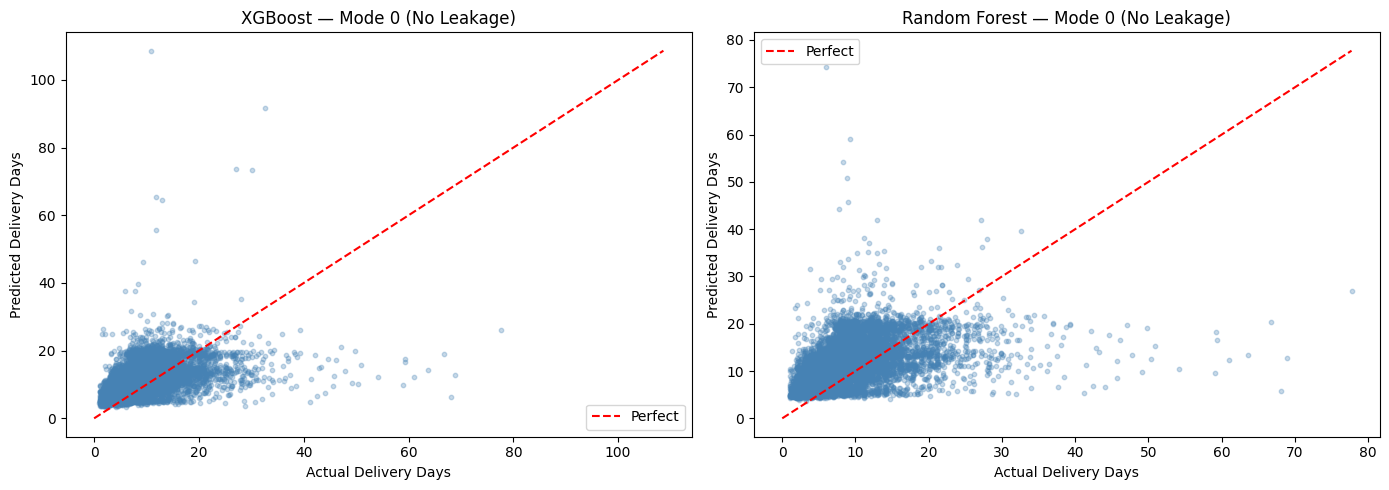

In [14]:
# Actual vs Predicted plots (Mode 0)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, preds, title in zip(axes, [pred_xgb, pred_rf], ['XGBoost', 'Random Forest']):
    ax.scatter(y_test, preds, alpha=0.3, s=10, color='steelblue')
    lim = [0, max(y_test.max(), preds.max())]
    ax.plot(lim, lim, 'r--', lw=1.5, label='Perfect')
    ax.set_xlabel('Actual Delivery Days')
    ax.set_ylabel('Predicted Delivery Days')
    ax.set_title(f'{title} — Mode 0 (No Leakage)')
    ax.legend()
plt.tight_layout()
plt.show()

## Leakage Test

We now re-train **including `is_late`** as a feature (Mode 1).  
`is_late = 1 if actual_delivery_days > estimated_delivery_days else 0`  
It directly encodes the target, so it **cannot be used in production**.  

**Purpose:** Upper-bound performance and confirm the algorithm works. The gap between modes quantifies the value of that outcome signal.

In [15]:
# --- Mode 1: With Leakage ---
include_leakage = 1
features_leak = [f for f in FEATURES_WITH_LEAKAGE if f in df.columns]

X_train_l = df_train[features_leak].fillna(0)
X_test_l  = df_test[features_leak].fillna(0)

xgb_l = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, random_state=42, n_jobs=-1)
xgb_l.fit(X_train_l, y_train)
pred_xgb_l = xgb_l.predict(X_test_l)

rf_l = RandomForestRegressor(n_estimators=200, max_depth=15, random_state=42, n_jobs=-1)
rf_l.fit(X_train_l, y_train)
pred_rf_l = rf_l.predict(X_test_l)

print('--- Mode 1: With Leakage ---')
m1_xgb = compute_metrics(y_test, pred_xgb_l, 'XGBoost (with leakage)')
m1_rf  = compute_metrics(y_test, pred_rf_l,  'Random Forest (with leakage)')

--- Mode 1: With Leakage ---
XGBoost (with leakage)               RMSE=5.68  MAE=4.22  R²=-0.1181  MAPE=69.21%
Random Forest (with leakage)         RMSE=5.83  MAE=4.24  R²=-0.1771  MAPE=69.10%


Top 15 Features:
                           feature  importance
                        same_state    0.462757
                 customer_state_SP    0.033077
                 customer_state_RJ    0.024167
                   seller_state_CE    0.013530
                 customer_state_AP    0.012813
                       distance_km    0.011948
primary_category_home_appliances_2    0.011589
                             month    0.010874
    primary_category_watches_gifts    0.010858
                 customer_state_PI    0.010756
 primary_category_office_furniture    0.010573
             primary_category_auto    0.010174
             primary_category_food    0.010010
                   seller_state_PR    0.009817
                 customer_state_MG    0.009758


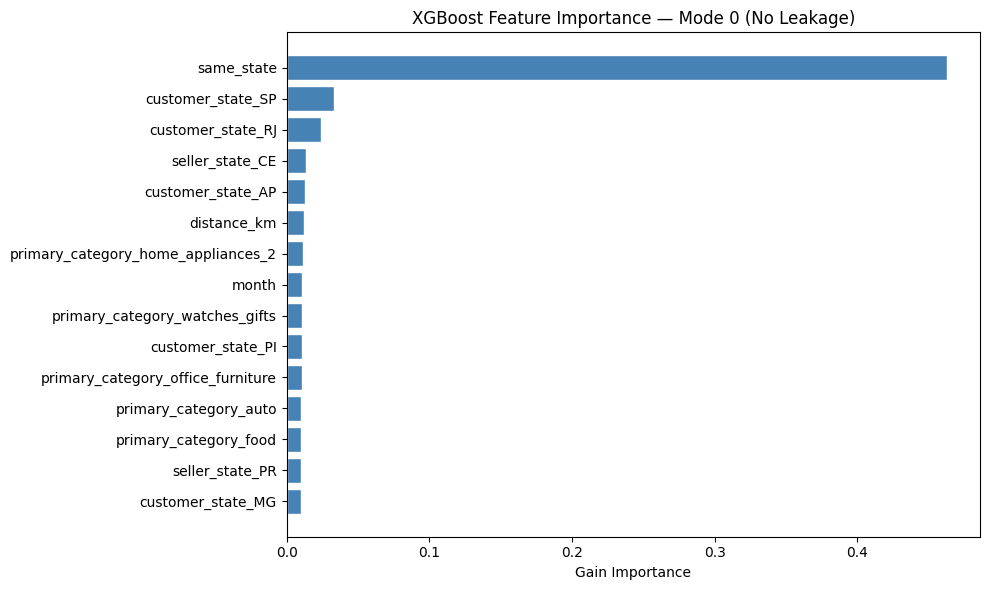

In [16]:
# --- Feature Importance (XGBoost, Mode 0) ---
importance_df = pd.DataFrame({
    'feature': X_train.columns,
    'importance': xgb.feature_importances_
}).sort_values('importance', ascending=False)

print('Top 15 Features:')
print(importance_df.head(15).to_string(index=False))

top15 = importance_df.head(15)
plt.figure(figsize=(10, 6))
plt.barh(top15['feature'][::-1], top15['importance'][::-1], color='steelblue', edgecolor='white')
plt.xlabel('Gain Importance')
plt.title('XGBoost Feature Importance — Mode 0 (No Leakage)', fontsize=12)
plt.tight_layout()
plt.show()

In [17]:
# === COMPREHENSIVE PRESENTATION TABLE ===
print('\n' + '='*130)
print('COMPREHENSIVE MODEL COMPARISON TABLE')
print('='*130)

comparison = pd.DataFrame({
    'Model / Category': [
        '1. OLIST BASELINE (Provided Estimate)',
        '',
        '2. MODE 0: NO LEAKAGE (Production Ready)',
        '   XGBoost',
        '   Random Forest',
        '   Best Mode 0',
        '',
        '3. MODE 1: WITH LEAKAGE (Sanity Check)',
        '   XGBoost',
        '   Random Forest',
        '   Best Mode 1',
        '',
        '4. LEAKAGE IMPACT ANALYSIS',
        '   Improvement (XGB): Mode 1 vs Mode 0',
        '   Improvement (RF): Mode 1 vs Mode 0',
    ],
    'RMSE (days)': [
        f'{baseline_rmse:.2f}',
        '',
        '',
        f'{m0_xgb["rmse"]:.2f}',
        f'{m0_rf["rmse"]:.2f}',
        f'{min(m0_xgb["rmse"], m0_rf["rmse"]):.2f}',
        '',
        '',
        f'{m1_xgb["rmse"]:.2f}',
        f'{m1_rf["rmse"]:.2f}',
        f'{min(m1_xgb["rmse"], m1_rf["rmse"]):.2f}',
        '',
        '',
        f'{(m0_xgb["rmse"] - m1_xgb["rmse"]):.2f} ({(m0_xgb["rmse"] - m1_xgb["rmse"]) / m0_xgb["rmse"] * 100:.1f}%)',
        f'{(m0_rf["rmse"] - m1_rf["rmse"]):.2f} ({(m0_rf["rmse"] - m1_rf["rmse"]) / m0_rf["rmse"] * 100:.1f}%)',
    ],
    'MAE (days)': [
        f'{baseline_mae:.2f}',
        '',
        '',
        f'{m0_xgb["mae"]:.2f}',
        f'{m0_rf["mae"]:.2f}',
        f'{min(m0_xgb["mae"], m0_rf["mae"]):.2f}',
        '',
        '',
        f'{m1_xgb["mae"]:.2f}',
        f'{m1_rf["mae"]:.2f}',
        f'{min(m1_xgb["mae"], m1_rf["mae"]):.2f}',
        '',
        '',
        f'{(m0_xgb["mae"] - m1_xgb["mae"]):.2f} ({(m0_xgb["mae"] - m1_xgb["mae"]) / m0_xgb["mae"] * 100:.1f}%)',
        f'{(m0_rf["mae"] - m1_rf["mae"]):.2f} ({(m0_rf["mae"] - m1_rf["mae"]) / m0_rf["mae"] * 100:.1f}%)',
    ],
    'R² Score': [
        f'{baseline_r2:.4f}',
        '',
        '',
        f'{m0_xgb["r2"]:.4f}',
        f'{m0_rf["r2"]:.4f}',
        f'{max(m0_xgb["r2"], m0_rf["r2"]):.4f}',
        '',
        '',
        f'{m1_xgb["r2"]:.4f}',
        f'{m1_rf["r2"]:.4f}',
        f'{max(m1_xgb["r2"], m1_rf["r2"]):.4f}',
        '',
        '',
        f'{m1_xgb["r2"] - m0_xgb["r2"]:.4f}',
        f'{m1_rf["r2"] - m0_rf["r2"]:.4f}',
    ],
    'MAPE (%)': [
        f'{baseline_mape:.2f}',
        '',
        '',
        f'{m0_xgb["mape"]:.2f}',
        f'{m0_rf["mape"]:.2f}',
        f'{min(m0_xgb["mape"], m0_rf["mape"]):.2f}',
        '',
        '',
        f'{m1_xgb["mape"]:.2f}',
        f'{m1_rf["mape"]:.2f}',
        f'{min(m1_xgb["mape"], m1_rf["mape"]):.2f}',
        '',
        '',
        f'{(m0_xgb["mape"] - m1_xgb["mape"]):.2f}',
        f'{(m0_rf["mape"] - m1_rf["mape"]):.2f}',
    ],
})

print(comparison.to_string(index=False))
print('='*130)



COMPREHENSIVE MODEL COMPARISON TABLE
                        Model / Category   RMSE (days)  MAE (days) R² Score MAPE (%)
   1. OLIST BASELINE (Provided Estimate)         12.47       10.15  -4.3901   160.91
                                                                                    
2. MODE 0: NO LEAKAGE (Production Ready)                                            
                                 XGBoost          5.68        4.27  -0.1163    70.77
                           Random Forest          5.70        4.32  -0.1265    71.76
                             Best Mode 0          5.68        4.27  -0.1163    70.77
                                                                                    
  3. MODE 1: WITH LEAKAGE (Sanity Check)                                            
                                 XGBoost          5.68        4.22  -0.1181    69.21
                           Random Forest          5.83        4.24  -0.1771    69.10
                           

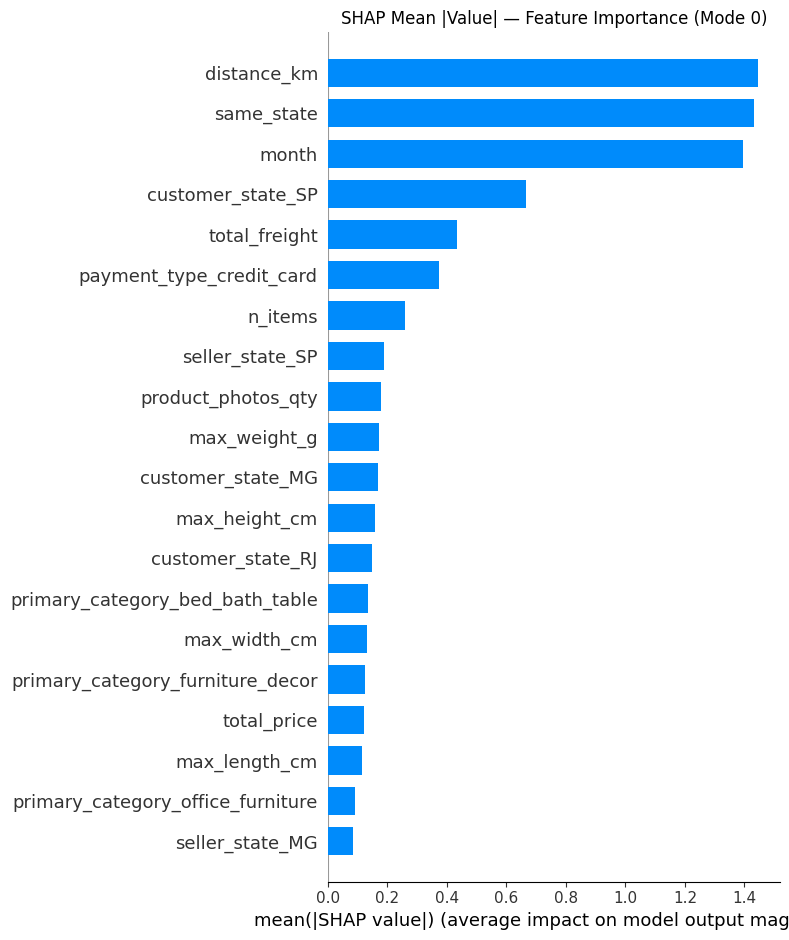

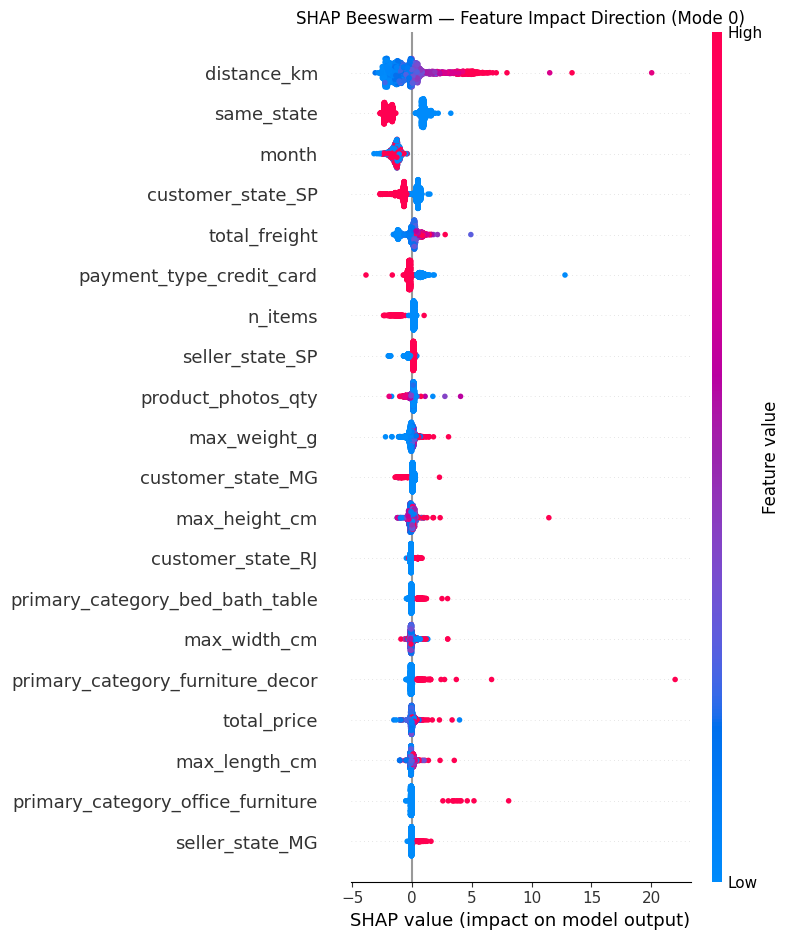

In [18]:
# --- SHAP Summary Plots ---
X_test_sample = X_test.sample(min(2000, len(X_test)), random_state=42)

explainer   = shap.TreeExplainer(xgb)
shap_values = explainer.shap_values(X_test_sample)

# Bar summary
shap.summary_plot(shap_values, X_test_sample, plot_type='bar', show=False)
plt.title('SHAP Mean |Value| — Feature Importance (Mode 0)')
plt.tight_layout()
plt.show()

# Beeswarm
shap.summary_plot(shap_values, X_test_sample, show=False)
plt.title('SHAP Beeswarm — Feature Impact Direction (Mode 0)')
plt.tight_layout()
plt.show()


Order 1  |  Actual: 13.8 days  |  Predicted: 14.8 days


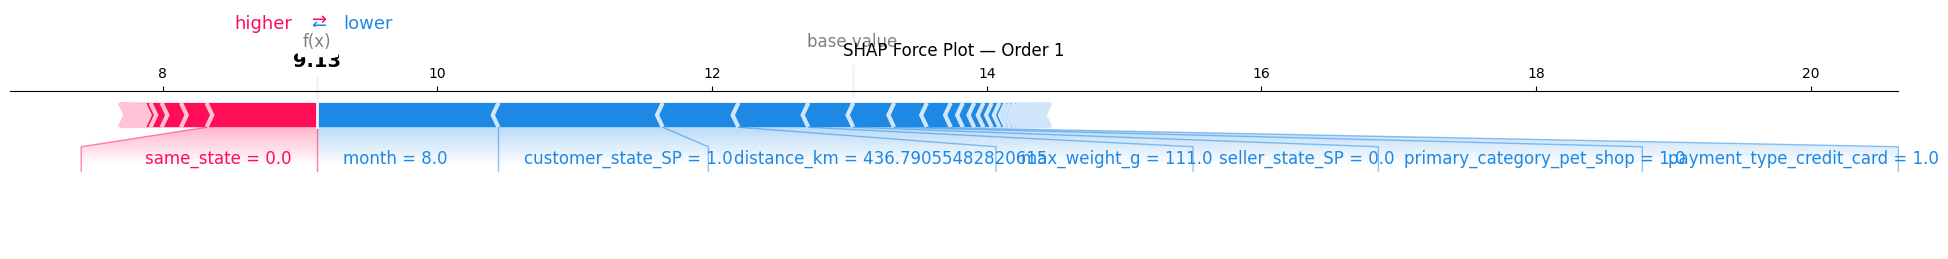


Order 2  |  Actual: 9.4 days  |  Predicted: 14.8 days


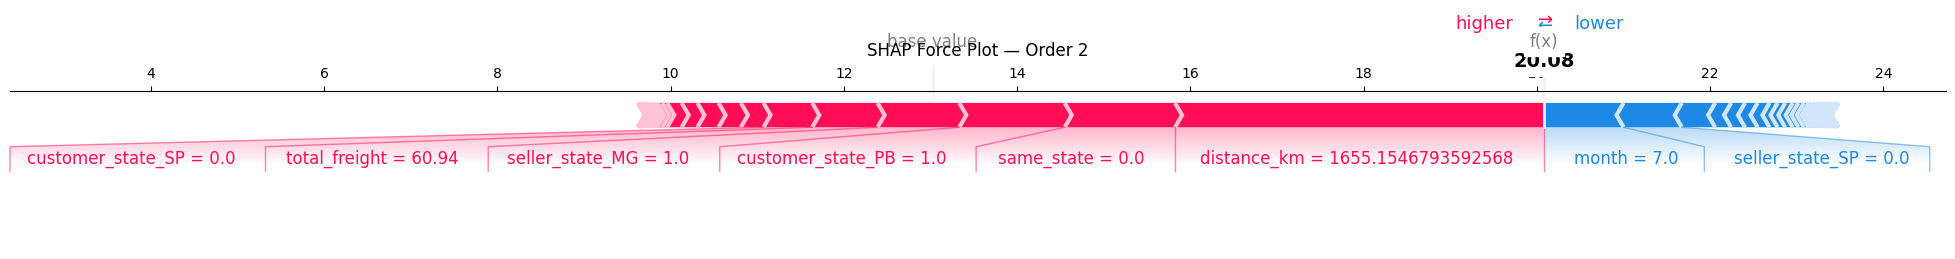

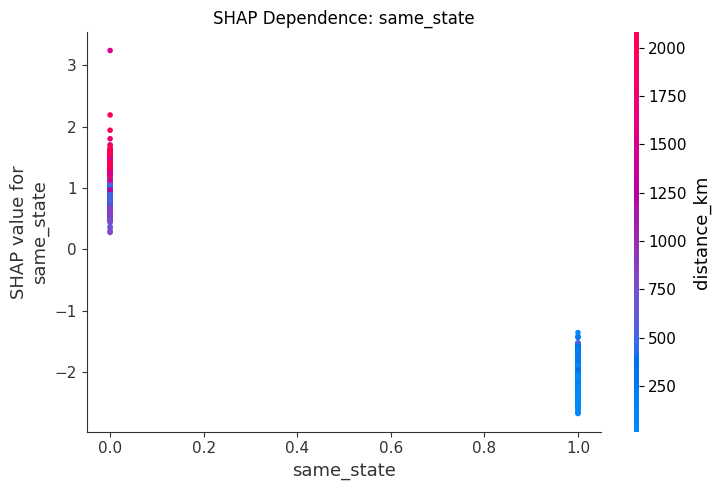

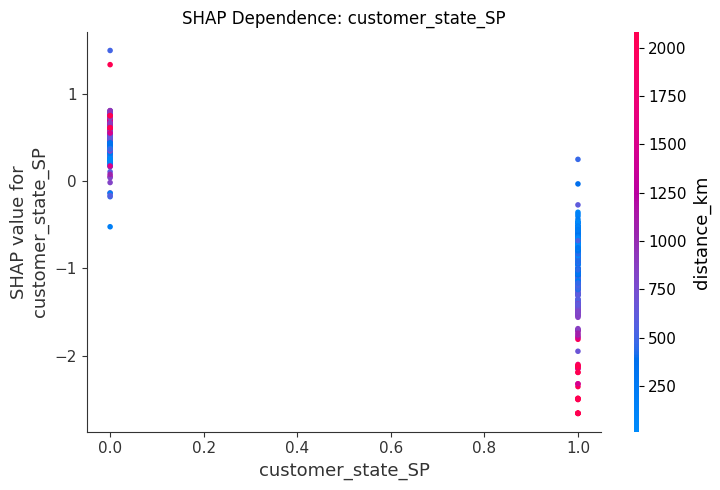

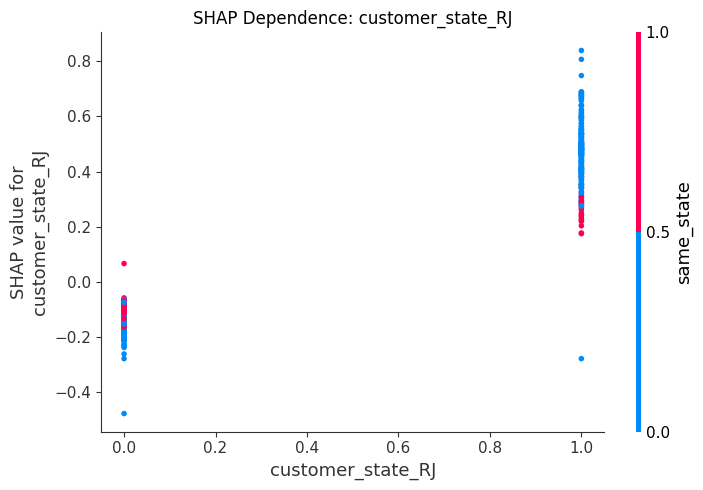

In [19]:
# --- Individual Prediction Explanations & Dependence Plots ---
for idx, label in enumerate(['Order 1', 'Order 2']):
    actual    = y_test.iloc[idx]
    predicted = pred_xgb[idx]
    print(f'\n{label}  |  Actual: {actual:.1f} days  |  Predicted: {predicted:.1f} days')
    shap.force_plot(
        explainer.expected_value,
        shap_values[idx],
        X_test_sample.iloc[idx],
        matplotlib=True,
        show=False
    )
    plt.title(f'SHAP Force Plot — {label}', pad=25)
    plt.tight_layout()
    plt.show()

# Dependence plots for top 3 features
for feat in importance_df['feature'].head(3).tolist():
    if feat in X_test_sample.columns:
        shap.dependence_plot(feat, shap_values, X_test_sample, show=False)
        plt.title(f'SHAP Dependence: {feat}')
        plt.tight_layout()
        plt.show()

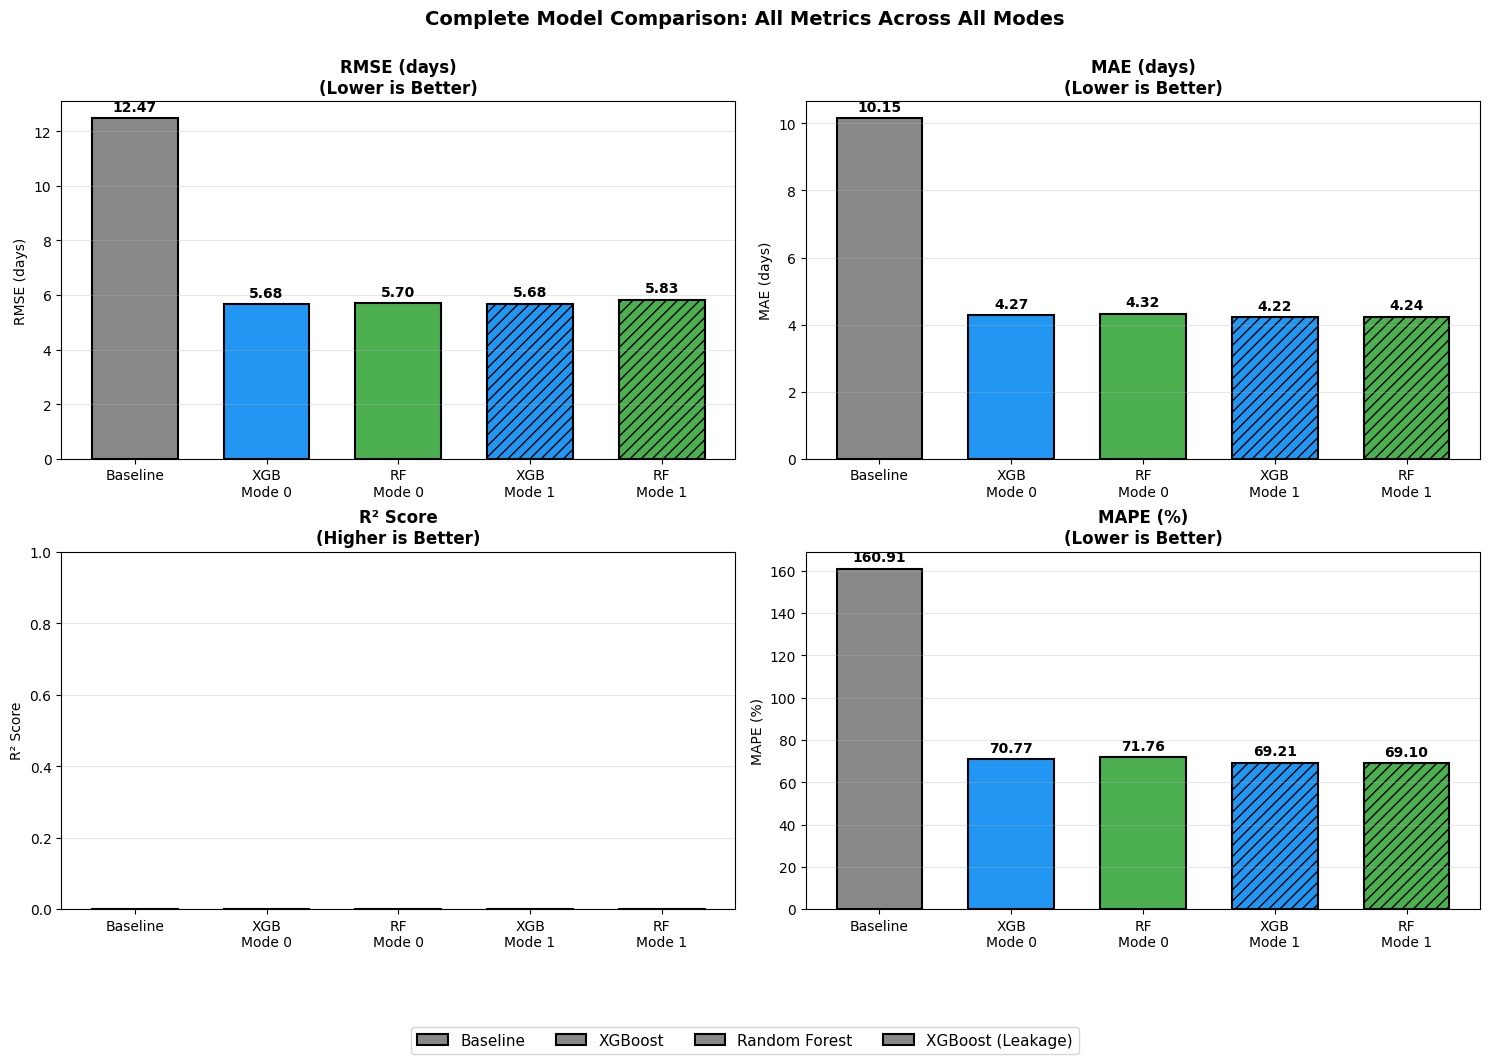

In [20]:
# === UPDATED BAR CHART: All Models + Modes ===
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

labels = ['Baseline', 'XGB\nMode 0', 'RF\nMode 0', 'XGB\nMode 1', 'RF\nMode 1']
rmses  = [baseline_rmse, m0_xgb['rmse'], m0_rf['rmse'], m1_xgb['rmse'], m1_rf['rmse']]
maes   = [baseline_mae, m0_xgb['mae'], m0_rf['mae'], m1_xgb['mae'], m1_rf['mae']]
r2s    = [baseline_r2, m0_xgb['r2'], m0_rf['r2'], m1_xgb['r2'], m1_rf['r2']]
mapes  = [baseline_mape, m0_xgb['mape'], m0_rf['mape'], m1_xgb['mape'], m1_rf['mape']]

colors = ['#888888', '#2196F3', '#4CAF50', '#2196F3', '#4CAF50']
hatches = [None, None, None, '///', '///']

metrics = [
    (rmses, 'RMSE (days)', 'Lower is Better'),
    (maes, 'MAE (days)', 'Lower is Better'),
    (r2s, 'R² Score', 'Higher is Better'),
    (mapes, 'MAPE (%)', 'Lower is Better'),
]

for ax, (vals, title, note) in zip(axes, metrics):
    bars = ax.bar(labels, vals, color=colors, edgecolor='black', linewidth=1.5, width=0.65, hatch=hatches)
    ax.bar_label(bars, fmt='%.2f', padding=3, fontsize=10, fontweight='bold')
    ax.set_title(f'{title}\n({note})', fontsize=12, fontweight='bold')
    ax.set_ylabel(title, fontsize=10)
    ax.grid(axis='y', alpha=0.3)
    if title == 'R² Score':
        ax.set_ylim(0, 1)

# Add legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#888888', label='Baseline'),
    Patch(facecolor='#2196F3', label='Mode 0 (No Leakage)'),
    Patch(facecolor='#4CAF50', label='Mode 0 (No Leakage)'),
    Patch(facecolor='#2196F3', hatch='///', label='Mode 1 (With Leakage)'),
    Patch(facecolor='#4CAF50', hatch='///', label='Mode 1 (With Leakage)'),
]
fig.legend(['Baseline', 'XGBoost', 'Random Forest', 'XGBoost (Leakage)', 'Random Forest (Leakage)'],
           loc='upper center', bbox_to_anchor=(0.5, -0.01), ncol=5, fontsize=11)

plt.suptitle('Complete Model Comparison: All Metrics Across All Modes', fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout()
plt.subplots_adjust(bottom=0.1)
plt.show()


Best model selected: XGBoost (Mode 0)


,actual_delivery_days,olist_predicted_days,best_model_predicted_days
0,13.782037,19.637755,14.789726
1,9.394213,27.139699,14.769467
2,4.922396,13.760984,9.814462
3,4.277627,8.010637,9.994237
4,1.968044,7.517454,5.413433
...,...,...,...
95,12.467176,24.528530,10.443392
96,18.142674,8.882454,8.031096
97,10.447870,16.441678,26.166264
98,15.833519,25.720278,20.343706


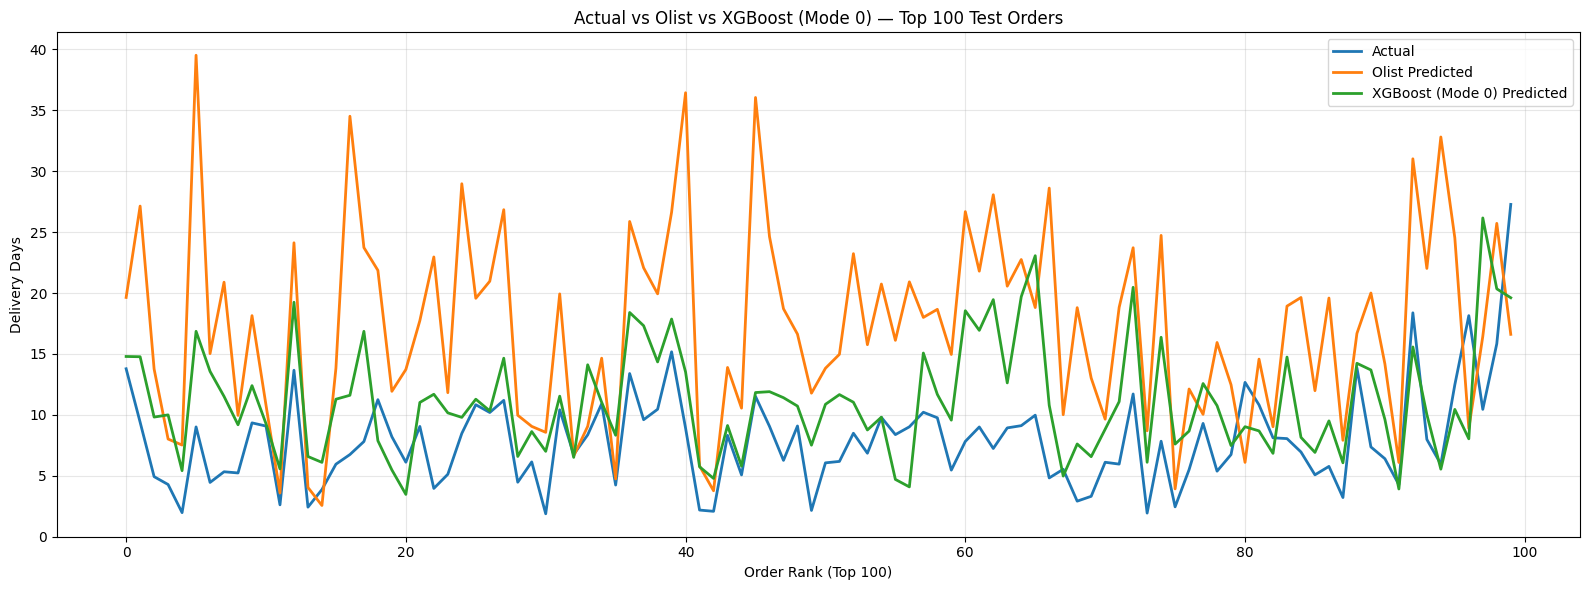

In [21]:
# Keep only the better model between XGBoost and Random Forest (Mode 0), based on RMSE
if m0_xgb['rmse'] <= m0_rf['rmse']:
    best_model_name = 'XGBoost (Mode 0)'
    best_pred = pred_xgb
else:
    best_model_name = 'Random Forest (Mode 0)'
    best_pred = pred_rf

print(f'Best model selected: {best_model_name}')

# Compare Actual vs Olist vs Best Model for first 100 test orders
comparison_top100 = pd.DataFrame({
    'actual_delivery_days': y_test.reset_index(drop=True),
    'olist_predicted_days': df_test['estimated_delivery_days'].reset_index(drop=True),
    'best_model_predicted_days': pd.Series(best_pred).reset_index(drop=True)
}).head(100)

display(comparison_top100)

# Plot
plt.figure(figsize=(16, 6))
plt.plot(comparison_top100.index, comparison_top100['actual_delivery_days'], label='Actual', linewidth=2)
plt.plot(comparison_top100.index, comparison_top100['olist_predicted_days'], label='Olist Predicted', linewidth=2)
plt.plot(comparison_top100.index, comparison_top100['best_model_predicted_days'], label=f'{best_model_name} Predicted', linewidth=2)

plt.title(f'Actual vs Olist vs {best_model_name} — Top 100 Test Orders')
plt.xlabel('Order Rank (Top 100)')
plt.ylabel('Delivery Days')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


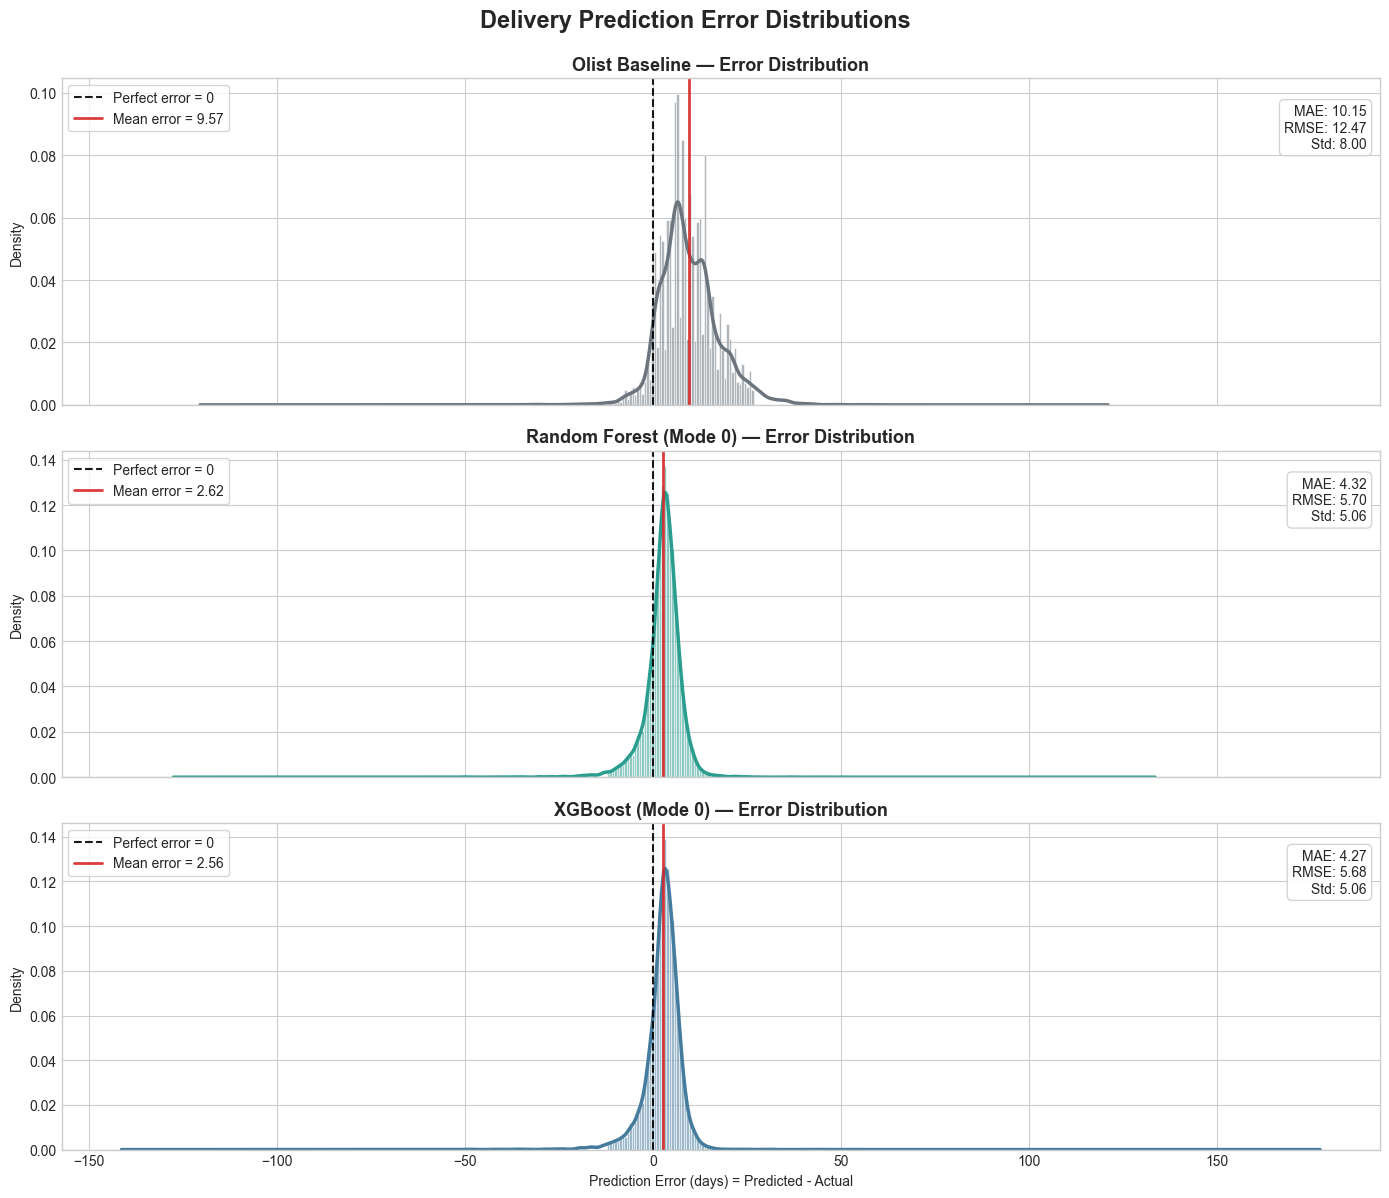

In [22]:
# Error distributions: Olist vs Random Forest vs XGBoost (separate plots)

# Residuals (prediction - actual): negative = early prediction, positive = late prediction
err_olist = df_test['estimated_delivery_days'].to_numpy() - y_test.to_numpy()
err_rf    = pred_rf - y_test.to_numpy()
err_xgb   = pred_xgb - y_test.to_numpy()

errors = [
    ("Olist Baseline", err_olist, "#6c757d"),
    ("Random Forest (Mode 0)", err_rf, "#2a9d8f"),
    ("XGBoost (Mode 0)", err_xgb, "#457b9d"),
]

# Shared x-range (robust to outliers)
all_err = np.concatenate([err_olist, err_rf, err_xgb])
x_min, x_max = np.percentile(all_err, [1, 99])
bins = np.linspace(x_min, x_max, 60)

plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

for ax, (name, e, color) in zip(axes, errors):
    s = pd.Series(e)

    # Histogram + KDE
    ax.hist(e, bins=bins, density=True, alpha=0.55, color=color, edgecolor="white", linewidth=0.8)
    s.plot(kind="kde", ax=ax, color=color, linewidth=2.5)

    # Reference lines
    ax.axvline(0, color="black", linestyle="--", linewidth=1.5, alpha=0.9, label="Perfect error = 0")
    ax.axvline(s.mean(), color="#d62828", linestyle="-", linewidth=2, alpha=0.9, label=f"Mean error = {s.mean():.2f}")

    # Stats box
    mae = np.mean(np.abs(e))
    rmse = np.sqrt(np.mean(e**2))
    ax.text(
        0.99, 0.92,
        f"MAE: {mae:.2f}\nRMSE: {rmse:.2f}\nStd: {s.std():.2f}",
        transform=ax.transAxes,
        ha="right", va="top",
        fontsize=10,
        bbox=dict(boxstyle="round,pad=0.35", facecolor="white", edgecolor="lightgray", alpha=0.95)
    )

    ax.set_title(f"{name} — Error Distribution", fontsize=13, fontweight="bold")
    ax.set_ylabel("Density")
    ax.legend(loc="upper left", frameon=True)

axes[-1].set_xlabel("Prediction Error (days) = Predicted - Actual")
fig.suptitle("Delivery Prediction Error Distributions", fontsize=17, fontweight="bold", y=0.995)
plt.tight_layout()
plt.show()